# Week 4 - Correlation Analysis, ANOVA & Linear Regression

## Markdown Language

## Research Investigation: IQ Data
[Willerman et al. (1991)](https://link.springer.com/chapter/10.1007/978-1-4757-3224-5_6) conducted their study at a large southwestern university. They selected a sample of 40 right-handed Anglo introductory psychology students who had indicated no history of alcoholism, unconsciousness, brain damage, epilepsy, or heart disease. These subjects were drawn from a larger pool of introductory psychology students with total Scholastic Aptitude Test Scores higher than 1350 or lower than 940 who had agreed to satisfy a course requirement by allowing the administration of four subtests (Vocabulary, Similarities, Block Design, and Picture Completion) of the Wechsler (1981) Adult Intelligence Scale-Revised. With prior approval of the University's research review board, students selected for MRI were required to obtain prorated full-scale IQs of greater than 130 or less than 103, and were equally divided by sex and IQ classification.

### Dataset Summary: 
- Nationality: The Country of Origin for the Individual.
- Sex: The born sex of the individual, separated into Male and Female.
- Full Scale IQ (FSIQ): This is the overall measure of an individual’s cognitive abilities, derived from combining the scores of all subtests in the WAIS-R. It represents a general estimate of intellectual functioning.
- Verbal Intelligence Quotient (VIQ): This score is derived from the verbal subtests of the WAIS-R and measures verbal reasoning, comprehension, and general knowledge. It reflects a person's ability to understand and use language, as well as their acquired knowledge.
- Performance Intelligence Quotient (PIQ):This score is based on the non-verbal, performance-based subtests. It measures problem-solving, spatial processing, and visual-motor integration. It is often used to assess an individual's ability to process and organize visual information and solve practical tasks.
- Magnetic Resonance Imaging (MRI) Count: The researchers used Magnetic Resonance Imaging (MRI) to determine the brain size of the subjects.

Utilising this Dataset we would like to investigate a number of research questions, that allow us to better understand the relationship between relative IQ metrics, as well as the performative difference between individuals from different nationalities and born-sex.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy import stats

In [6]:
iqdata = pd.read_csv("./data/iqdata.csv")
iqdata.head()

,Nationality,Sex,FSIQ,VIQ,PIQ,MRI_Count
0,British,Female,133,132,124,816932
1,British,Male,140,150,124,1001121
2,British,Male,139,123,150,1038437
3,Spanish,Male,133,129,128,965353
4,British,Female,137,132,134,951545


 ## Research Question 1:

Given that FSIQ is the Full-Scale IQ measurement. We would like to investigate <u>*Is there a relationship between and individuals Full Scale IQ Score, and Magnetic Resonance Imaging (MRI) Count?*</u>. In order to complete this analysis, we must select the appropriate Hypothesis test for statistical analysis.

The following hypothesis:

- **Relationship between two variables**

Would be most appropriate.

### Hypothesis Statement:

- $H_0 = \rho$
- $H_1 \neq \rho$

The null hypothesis $H_0$, states that there is no correlation $\rho$ between the two variables, *FSIQ* and *MRI*. Meaning the <u>population</u> correlation between these two variables is equal to zero, and thus *MRI* has no association with *FSIQ*.

The two-tailed alternative hypothesis $H_1$, states that there exists a correlation $\rho$ between the two variables, *FSIQ* and *MRI*.  Meaning the <u>population</u> correlation between these two variables is not zero. Hence, there exists either a positive or negative correlation between *MRI* and *FSIQ*.

### Assumptions:

- Linearity (Test not Required): We assume that if a relationship exists between the variables *MRI* and *FSIQ*. That it is a **linear** relationship and not a **non-linear** relationship.
- Normality (Test Required): Both variables must be **normally distributed** in order to utilise the **pearson correlation**. As such this research will investigate this assumption.
- Homoscedacity: The variance of the residuals (or errors) should be constant across all levels of the independent variable.
- Independence: The observations must be **independent** of one another. 

In [7]:
# Assumption 2 - Normality:
print(f"Assumption test: Normality [FSIQ] | {stats.shapiro(iqdata['FSIQ'])}")
print(f"Assumption test: Normality [MRI Count] | {stats.shapiro(iqdata['MRI_Count'])}")

Assumption test: Normality [FSIQ] | ShapiroResult(statistic=np.float64(0.8300553302840135), pvalue=np.float64(3.057070446944554e-05))
Assumption test: Normality [MRI Count] | ShapiroResult(statistic=np.float64(0.9712711882549291), pvalue=np.float64(0.3945132426357154))


<Axes: ylabel='Density'>

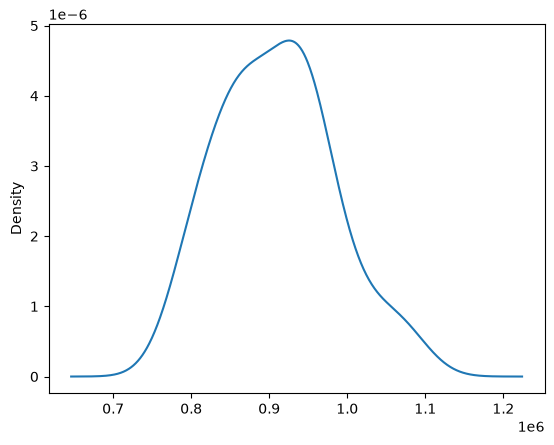

In [8]:
iqdata["MRI_Count"].plot(kind="density")

<Axes: ylabel='Density'>

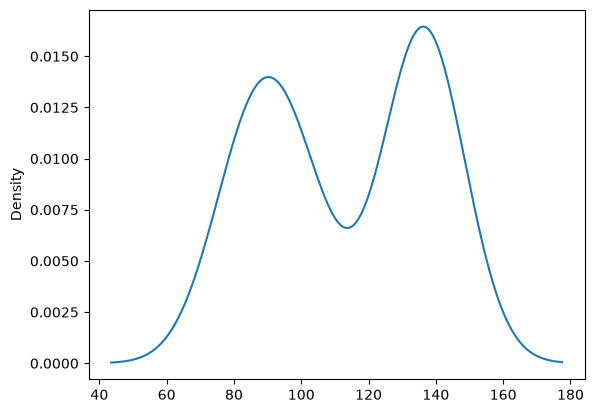

In [9]:
iqdata["FSIQ"].plot(kind="density")

The Shaprio-Wilks test states the following $(\alpha = 0.05)$:

- $H_0$: The data is normally distributed
- $H_1$: THe data is not normally distributed

Given the p-values from the test conducted on FSIQ (Full-Scale IQ), an incredibly small p-value is observed. Suggesting that we reject the null hypothesis, that the Full-Scale IQ is normally distributed. This is further evidenced by the denisty plot provided of FSIQ, which shows to separate peaks within the data, which is not indicative of a normal distribution with a single peak and equal length tails.

Given the p-valeus from the test conducted on MRI (Magnetic Resonance Imaging) Count, a relatively large p-value can be observed. A p-value of 0.394 would suggests there's an approximately 40% chance that the population data is normally distributed. As such, we should not reject the null hypothesis at the 5% level. This is further evidenced by the density plot which shows something akin to a normal distribution, with a singular peak and equal length tails.

**Outcome:** We are required to use the non-normal alternative for our test, the **Spearman Correlation**
The following assumptions are no longer required:
- *Linearity*
- *Homoscedacity*

As these are only required for the **normally distributed** version of the test.

In [ ]:
corr, _ = stats.spearmanr(iqdata["FSIQ"], iqdata["MRI_Count"])

print(f"The Correlation value between FSIQ & MRI Count is: {corr}")

The Correlation value between FSIQ & MRI Count is: 0.47214191583899207


The correlation analysis would suggest a $\rho = 0.47214$ between Magnetic Reasonance Imaging and Full-Scale IQ. This would a positive association, that is as Brain Size (MRI Count) increases then the Full-Scale IQ of an individual also increases. The value would suggest a *Moderate Correlation* between the two variables.

A scatter plot can be used, to provide further evidence of the relationship between these two variables, and it's strength.

<Axes: title={'center': 'Correlation of MRI Count vs. FSIQ Score'}, xlabel='MRI Count', ylabel='FSIQ'>

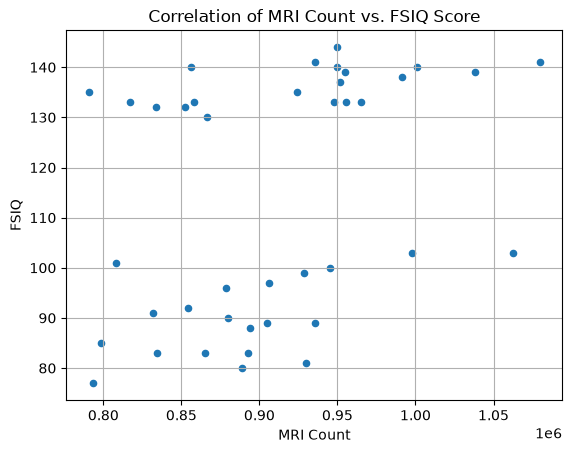

In [11]:
iqdata.plot(kind="scatter", x="MRI_Count", y="FSIQ",
            title = "Correlation of MRI Count vs. FSIQ Score",
            xlabel = "MRI Count",
            ylabel = "FSIQ",
            grid=True)

The visualization provides some interesting insights into our research question and conlusion:
- **Supports Positive Relationship** It's evident that there is a positive relationship between the two variables, as an individuals brains size increases there is an increase in FSIQ.
- **Strength of relationship is only moderate, not strong or very strong** There are a number of individuals a lower MRI count and still retain an above average Full Scale IQ. Likewise the individual with the largest FSIQ, has an average MRI count. However when you look at indivdiuals with an MRI Count of greater than 0.95 there's clearly more above average intelligence individuals.
- **Missing Data?** Given that FSIQ is a continuous variable. It's interesting to see that the data has no results for indivudals between 105 and 125 FSIQ. I would recommend this be investigated and if necessary more data be collected.

To reiterate:

The correlation analysis would suggest a $\rho = 0.47214$ between Magnetic Reasonance Imaging and Full-Scale IQ. This would a positive association, that is as Brain Size (MRI Count) increases then the Full-Scale IQ of an individual also increases.

##### Additional Notes:
In this example we didn't need to check for the following assumption. Here's how we could do this.

- Homoscedacity: https://www.statology.org/linear-regression-assumptions/, https://www.statology.org/heteroscedasticity-regression/, https://www.statology.org/breusch-pagan-test/
- Independence: https://www.statology.org/durbin-watson-test/

We will see these again when we come to Linear Regression!

---
# Different Dataset - Research Question 1:

The previous example has shown you how to setup a research question for a given dataset, and provide motivation to investigating this question. We could continue on in this vein and continue to investigate the same dataset. However, to provide some variety in the taught session, we will investigate a different dataset.

I won't go through the same pains as I previously did to clearly outline the dataset and research topic motivation.

In [12]:
schooldata = pd.read_csv("./data/primary_school.csv")
schooldata.head()

,Country,Height
0,Wales,56.424477
1,Wales,52.886270
2,Wales,54.298225
3,Wales,54.832002
4,Wales,59.640548


We would like to investigate the following research question:
- **Is there a difference in the heights of school children from different countries in the UK? Specificially England, Wales, Scotland and Northen Ireland.**

Given that we have multiple independent variables in the form of heights of children from separate countries, the most appropriate tests would be a **One-Way ANOVA** or **Kruskal-Wallis Test** depending on if the assumptions are held for the **ANOVA**.


### Hypothesis Statment:

- $H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4$
-  $H_1: \mu_i \neq \mu_j$

The null hypothesis states that the mean height of all groups is the same. That is, that the mean height of children from each country in the UK is the same.

The alternative hypothesis states that the mean height of at least one group, differs from the others. That is, the mean height of children from at least one of our countries deviates significantly (taller or shorter) from the rest.

**Note**: If we use the non-distributed test, then mean is replaced for **median** in the above statements.


### Assumptions:
- Dependent Variable in continuous (Not-Tested): The heights of children measured in a continuous variable. Any value (to a certain measurement accuracy, in this case 6 decimal places) can be used.
- Independent Observations (Not-Tested): There cannot be a single child that is measured more than once, and appears in more than one group. Given this is by country, we can safely assume that one child is not been measured twice, in two separate countries.
- Normally Distributed (Tested): The heights of students from each country, must follow a normal distribution. This can be tested for.
- Equal Variance (Homogenity of Variances, Tested): The heights of students from each country, have a similar spread in terms of short, tall and medium height individuals.  This can be tested for via the <u>Levene's Test</u>.

In [41]:
# Assumption 1: Normally Distributed (alpha = 0.05)
func = stats.shapiro
norm_test = schooldata.groupby(by="Country")["Height"].apply(func)

print(f"England: {norm_test['England']} \nWales: {norm_test['Wales']} \nScotland: {norm_test['Scotland']}\nN Ireland: {norm_test['N Ireland']}")

England: ShapiroResult(statistic=np.float64(0.9844805850937928), pvalue=np.float64(0.9572306155196642)) 
Wales: ShapiroResult(statistic=np.float64(0.9539488209418255), pvalue=np.float64(0.3071205703172837)) 
Scotland: ShapiroResult(statistic=np.float64(0.96845037678244), pvalue=np.float64(0.6060685758110573))
N Ireland: ShapiroResult(statistic=np.float64(0.9802141316138903), pvalue=np.float64(0.8893195827442035))


array([<Axes: title={'center': 'England'}, ylabel='Frequency'>,
       <Axes: title={'center': 'N Ireland'}, ylabel='Frequency'>,
       <Axes: title={'center': 'Scotland'}, ylabel='Frequency'>,
       <Axes: title={'center': 'Wales'}, ylabel='Frequency'>],
      dtype=object)

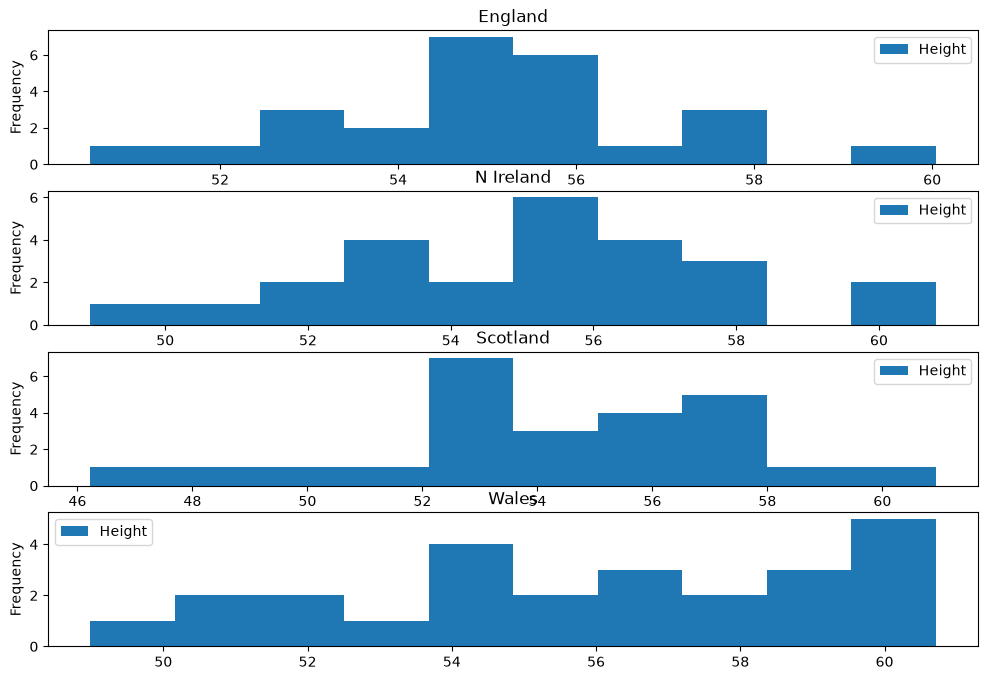

In [14]:
schooldata.plot(kind="hist", by="Country", column=["Height"],
                figsize=(12,8))

The Shaprio-Wilks test states the following $(\alpha = 0.05)$:

- $H_0$: The data is normally distributed
- $H_1$: The data is not normally distributed

Given that the p-value for each group is significantly above the 5% cut-off, we do not have evidence to reject the null hypothesis that the data for each group is normally distributed.

That is, we operate under the assumption that the heights of children from each indivudal country (England, Wales, Scotland and Northern Ireland) is normally distributed.

Meaning we need to check out second assumption.

In [15]:
# Assumption 2: Equality of Variance

england_df = schooldata[schooldata["Country"] == "England"]["Height"]
wales_df = schooldata[schooldata["Country"] == "Wales"]["Height"]
scotland_df = schooldata[schooldata["Country"] == "Scotland"]["Height"]
ireland_df = schooldata[schooldata["Country"] == "N Ireland"]["Height"]


lev_result = stats.levene(england_df, wales_df, scotland_df, ireland_df)

print(f"The Levene's Test: {lev_result}")

The Levene's Test: LeveneResult(statistic=np.float64(2.4243325130064046), pvalue=np.float64(0.07042101785101365))


The Levene's test states the following $(\alpha = 0.05)$:

- $H_0: \sigma_1 = \sigma_2 = \sigma_3 = \sigma_4$
- $H_1: \sigma_i \neq \sigma_j$

The null hypothesis states that the variance of each group is equal. That is, the variance in heights for each country are the same.

The alternative hypothesis states that the variance of at-least one group is different from the others. That is, the variation in height for at least one country, is different from the other countries.

Given our statistical output a p-value of 0.07 which is greater than 0.05. At the 5% significance level, we fail to reject the null hypothesis that the variance of each group, and thus heights from different countires, is the same. 


**Given this, all assumption have now been met. We can conduct the normally-distributed ANOVA test**

In [16]:
stats.f_oneway(england_df,wales_df,scotland_df,ireland_df)

F_onewayResult(statistic=np.float64(1.1729546361730523), pvalue=np.float64(0.32417952298327607))

Conducting the One-Way ANOVA test return a p-value of 0.32. Suggesting that there is insufficent evidence to reject the null hypothesis at the 5% significance level. That hypothesis being that the mean height of all groups is the same. That is, that the mean height of children from each country in the UK is the same.

We can produce a box-plot to provide further evidence and insight of this claim:

Height    Axes(0.125,0.11;0.775x0.77)
dtype: object

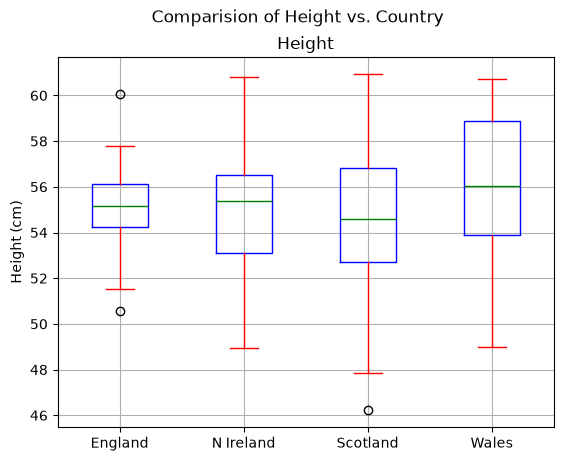

In [17]:
schooldata.plot(kind="box", by="Country", column=["Height"],
                color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
                title="Comparision of Height vs. Country",
                ylabel="Height (cm)",
                grid=True)

The box-plot provides insight into our data:
- Median values are very similar: The median value, represented by the green line, are very similar between each group. We can define this by noticing that the median for each group, is contained within the 25% and 75% bounding boxes of every other group. Suggesting high similarity between groups.
- Wales appears higher, but not statistically significant: The boxplot from wales suggests that the children may be taller, with a larger median and noticeably larger 75% percentile. However, the 95th percentiles for this group fall in line with the others. And so this perhaps evident of some differing variance in the data, where our levene's test was close to the 5% cut off. At a population level, we have no evidence to suggest children from Wales are taller.
- England has a tight distribution: Again with our Levene's test being close to the 5% cut off, we can see that the median height of children in this group is mostly the same, with a tigher grouping of children heights than the other groups. However, no evidence was found to suggest at a population level, that England has taller or smaller children, or a difference in how the heights of their children vary.

---
# Linear Regression: One Variable

Given the following dataset on student study hours, and their test score. Build a predictive model that can predict their test-score, using hours studied as an input variable.

**What would be score of a student who studied for 9 hours?**

In [18]:
hours = [1,2,4,5,5,6,6,7,8,10,11,11,12,12,14]
score = [64,66,76,73,74,81,83,82,80,88,84,82,91,93,89]

data = {"Hours": hours, "Score": score}

test_score = pd.DataFrame(data)
test_score.head()

,Hours,Score
0,1,64
1,2,66
2,4,76
3,5,73
4,5,74






https://www.statology.org/linear-regression-assumptions/

## Assumptions

These assumptions are pulled from https://www.statology.org/linear-regression-assumptions/, and should be re-written in your own words when conducting statistical analysis.

- Assumption 1 - Linear Relationship (Scatter Plot): The first assumption of linear regression is that there is a linear relationship between the independent variable, x, and the independent variable, y.
- Assumption 2 (Durbin Watson Test - https://www.statology.org/durbin-watson-test/): The next assumption of linear regression is that the residuals are independent. This is mostly relevant when working with time series data. Ideally, we don’t want there to be a pattern among consecutive residuals. For example, residuals shouldn’t steadily grow larger as time goes on.

<Axes: xlabel='Hours', ylabel='Score'>

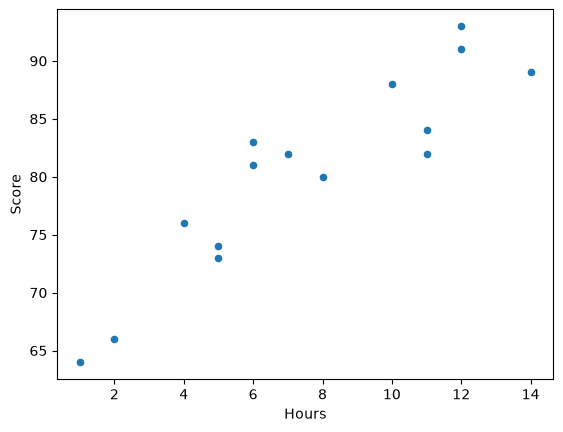

In [19]:
# Assumption 1 - Linear Relationship [SCATTER PLOT]
test_score.plot(kind="scatter", x="Hours", y="Score")

Based on the visualization, there appears to be a linear trending relationship between the hours of study, and the score an individual recieves on their test.

Our other assumptions will be tested, after the analysis.

In [20]:
# Linear Regression - SciPy Package:
results =  stats.linregress(x=test_score["Hours"],y=test_score["Score"])
print(results)

LinregressResult(slope=np.float64(1.9823747680890536), intercept=np.float64(65.3339517625232), rvalue=np.float64(0.9115809192514573), pvalue=np.float64(2.252709322350792e-06), stderr=np.float64(0.24796375257533915), intercept_stderr=np.float64(2.105989497342061))


- Slope: The Slope of the line is 1.98. Meaning that for every hours a student studies, the model predicts that there score on the test will increase by 1.98 (almost 2%).
- Intercept: The Intercept of the line is 65.33. Meaning that, if a student does not study any hours. They are predicted a score of 65.33 (65%) in the test.
- R^2: With an r-value of 0.9115, which can be squared for 0.83. Means that the model explains 83% of the variation in the test score results. Which is overall very good.

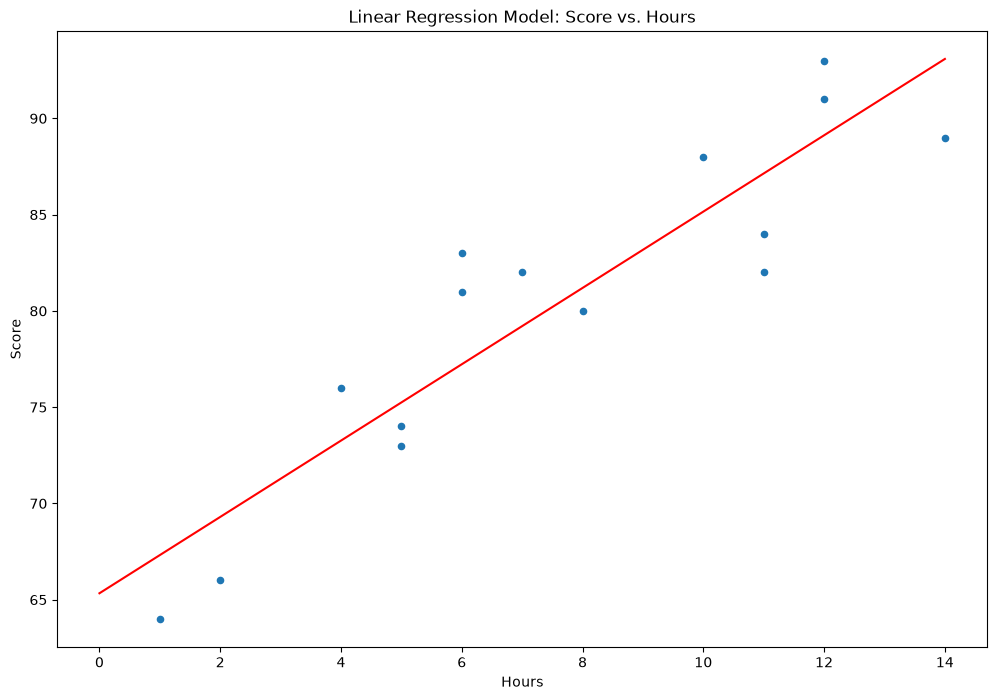

In [21]:
test_score.plot(kind="scatter", x="Hours", y="Score",
                title = "Linear Regression Model: Score vs. Hours",
                figsize=(12,8))
plt.plot([0,14], [results[1],14*results[0] + results[1]], color='r') 

In order to validate these results, we must ensure that the <u>Residuals</u> are normally distributed. Note: Residual is the distance of the point from the line. In order for these to be normally distributed, there need to be equal number of points above and below the line, adding up to roughly the same distance away.

In [22]:
test_score["Prediction"] = test_score["Hours"]*results[0] + results[1]
test_score

,Hours,Score,Prediction
0,1,64,67.316327
1,2,66,69.298701
2,4,76,73.263451
3,5,73,75.245826
4,5,74,75.245826
5,6,81,77.228200
6,6,83,77.228200
7,7,82,79.210575
8,8,80,81.192950
9,10,88,85.157699


In [23]:
test_score["Residuals"] = test_score["Score"] - test_score["Prediction"]
test_score

,Hours,Score,Prediction,Residuals
0,1,64,67.316327,-3.316327
1,2,66,69.298701,-3.298701
2,4,76,73.263451,2.736549
3,5,73,75.245826,-2.245826
4,5,74,75.245826,-1.245826
5,6,81,77.228200,3.771800
6,6,83,77.228200,5.771800
7,7,82,79.210575,2.789425
8,8,80,81.192950,-1.192950
9,10,88,85.157699,2.842301


Normality Shaprio Wilk Score: ShapiroResult(statistic=np.float64(0.9142149682160576), pvalue=np.float64(0.15713240685428326))


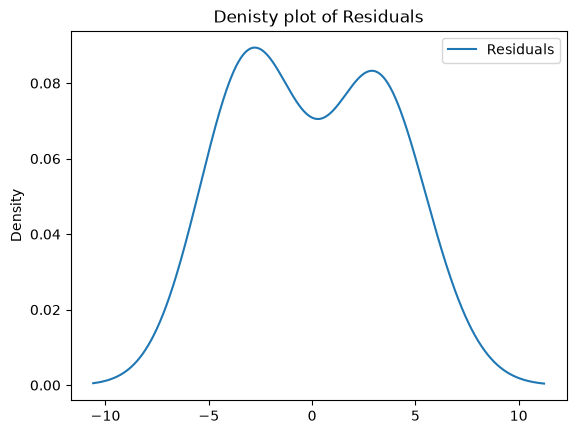

In [24]:
# Assumption 2 - Residuals

test_score.plot(kind="density", y="Residuals",
                title="Denisty plot of Residuals")
print(f"Normality Shaprio Wilk Score: {stats.shapiro(test_score['Residuals'])}")

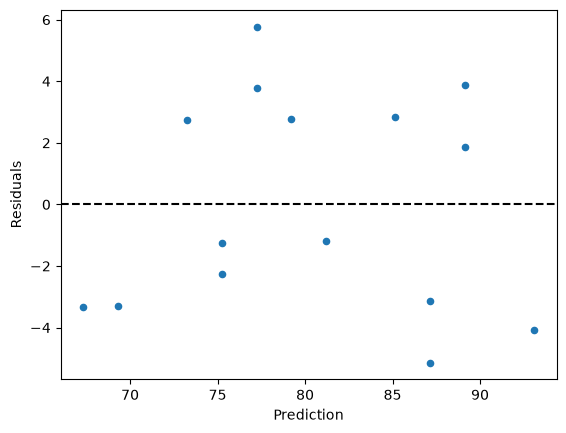

In [25]:
test_score.plot(kind="scatter", x="Prediction", y="Residuals")
plt.axhline(y=0, linestyle='--', color='k')

At the 5% significance level, there is not enough evidence to reject the null hypothesis that the data is normally distributed. Meaning there is not sufficient evidence to reject that the residuals of the linear regression, are normally distributed. Which supports in validating the results from our Linear Regression.

**Assumption 3 - Durbin Watson Test**
H0 (null hypothesis): There is no correlation among the residuals.

HA (alternative hypothesis): The residuals are autocorrelated.

The test statistic is approximately equal to 2*(1-r) where r is the sample autocorrelation of the residuals. Thus, the test statistic will always be between 0 and 4 with the following interpretation:

A test statistic of 2 indicates no serial correlation.
The closer the test statistics is to 0, the more evidence of positive serial correlation.
The closer the test statistics is to 4, the more evidence of negative serial correlation.

In [26]:
# Assumption 3 - Independent Variables
from statsmodels.stats.stattools import durbin_watson

durbin_watson(test_score.Residuals)

np.float64(1.6766107533775803)

### Alternative Package for Linear Regression

In [27]:
hours = [1,2,4,5,5,6,6,7,8,10,11,11,12,12,14]
score = [64,66,76,73,74,81,83,82,80,88,84,82,91,93,89]

data = {"Hours": hours, "Score": score}

test_score = pd.DataFrame(data)
test_score.head()

,Hours,Score
0,1,64
1,2,66
2,4,76
3,5,73
4,5,74


In [28]:
predictor_variables = test_score["Hours"]
predictor_variables = sm.add_constant(test_score["Hours"])

response_variable = test_score["Score"]

model = sm.OLS(response_variable, predictor_variables).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     63.91
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.25e-06
Time:                        12:38:12   Log-Likelihood:                -39.594
No. Observations:                  15   AIC:                             83.19
Df Residuals:                      13   BIC:                             84.60
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         65.3340      2.106     31.023      0.0

This provides statistics as part of its output that we had to previously manually calculate such as the Durbin-Watson Statistic. 

In [29]:
# We could re-create the same residual plot we've done previously
model.resid

0    -3.316327
1    -3.298701
2     2.736549
3    -2.245826
4    -1.245826
5     3.771800
6     5.771800
7     2.789425
8    -1.192950
9     2.842301
10   -3.140074
11   -5.140074
12    1.877551
13    3.877551
14   -4.087199
dtype: float64

In [30]:
predictor_variables.head()

,const,Hours
0,1.0,1
1,1.0,2
2,1.0,4
3,1.0,5
4,1.0,5


In [31]:
pred = np.array([1, 9])
model.predict(pred)

# Model Predicts that a student who studies for 9 hours will get 83% on the assessment.

array([83.17532468])

---

# Multiple Linear Regression

This notebook, demonstrates how to conduct & interprete a **multiple linear regression**:
For more information, see: https://www.statology.org/linear-regression-python/


## Import Packages:

The following packages are utilised to undertake this task:

1. Pandas - For Data Manipulation & Data Visualisation.
2. Matplotlib - Utilised in Combination with Pandas for Data Visualisation.
3. statsmodels - A statistics module, that simplifies the completion of a linear regression.

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

## Importing Dataset:

Using the <u>read_csv</u> functionality within pandas, we are going to read in the "apprasials" dataset.

In [33]:
df = pd.read_csv("./data/APPRAISAL.csv")
df.head()

,PropertyValue,LandValue,ImprovementValue,PropertyArea
0,68900,5960,44967,1873
1,48500,9000,27860,928
2,55500,9500,31439,126
3,62000,10000,39592,1265
4,116500,18000,72827,2214


A property appraiser wants to understand the value of a property in a rural area, that he cannot get to physically. So instead, he decides to <u>model</u> the value of the property. 

His opinion is that this can be modeled efficiently by using three key variables, namely:

- **Land Value:** appraised land value (£'s);
- **Improvement Value**: The added value to the property based on renevations and other factors.
- **Property Area:** area of the property (square feet).


Do you recommend that the property appraise would be wise to use such a model?

**Proposed Model: Multiple Linear Regression**

Using our statistical inference sheet, we can see that the hypohthesis of such a question, would fit "Linear relationship between a depedent variable (the one you are trying to predict), and two or more independent variables. As such we will use a ***Multiple Linear Regression***

Mathematical Formula:
$y = b_{1}x_{1} + b_{2}x_{2} + b_{3}x_{3} + c$

- $x_{1}$, $x_{2}$, $x_{3}$, represent the three feature variables from the data (Land Value, Improvement Value & Property Area).
- $b_{1}$, $b_{2}$, $b_{3}$, represent the parameters of the model which can be trained based on the data.
- $c$ represents the intercept (base value), without considering the other features.


This function (OLS) Ordinary Least Squares, is used to conduct the Multiple Linear Regression in statsmodels:

https://www.statsmodels.org/devel/generated/statsmodels.regression.linear_model.OLS.html

In [34]:
# Dependent Variable (y):
y = df['PropertyValue']


# Predictior/ Independent Variables (x): -> These variables adjust the slope of the line.
x = df[['LandValue', 'ImprovementValue', 'PropertyArea']]


# Add Constant to the Model: -> Adds a constant (c) which moves the line up and down
x = sm.add_constant(x)

# Fit Linear Regression Model:
model = sm.OLS(y, x).fit()

# Print model output:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          PropertyValue   R-squared:                       0.881
Model:                            OLS   Adj. R-squared:                  0.859
Method:                 Least Squares   F-statistic:                     39.45
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.28e-07
Time:                        12:38:12   Log-Likelihood:                -207.18
No. Observations:                  20   AIC:                             422.4
Df Residuals:                      16   BIC:                             426.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             5938.2283   5417.296  

### Interpretation of Initial Model


There are a number of interesting statistics that we can observe, some of which will inform that we need to update out model:

- R-Squared - 0.881: Determines how well out model with the current features fits the data. E.g. "88.1% of the variation in Property Value, can be explained by our three features (Land Value, Improvement Value, Property Value).
- coef (stand for coefficents in table 2): The coef values of 5938.2283, 1.0016, 0.9448, 6.0987, Are the values of $c$, $b_{1}$, $b_{2}$, $b_{3}$ respectively. **Example 1:** "A coefficient value of 6.0987 means that for every unit increase in Property Area (1 square foot increase) the value of the property increase by £6.10p" **Example 2:** "A constant of 5938.2283, means that the value of a house with 0 property area, 0 land value, and 0 improvement value is £5938.23p, in the context of this question, it would make no sense for a house to be zero size (property area = 0), meaning such an interpretation would not be suitable".
- P>|t|: The values 0.289, 0.081, 0.000, 0.252, tell you whether or not the inclusion of those variables within the model is <u>statistically significant</U>. At the **5% significance level**, if the variable has ***less than 5% (0.05), means the variable is statistically significant. Greater than 5%, means the variable is <u>not</u> statistically significant***.


The P|t| values would suggest that we could remove the, constant, property area, & land value. We will remove the features one by one, as the P>|t| value can change.

## Removing Constant

In [35]:
# Dependent Variable (y):
y = df['PropertyValue']


# Predictior/ Independent Variables (x): -> These variables adjust the slope of the line.
x = df[['LandValue', 'ImprovementValue', 'PropertyArea']]


# Add Constant to the Model: -> Adds a constant (c) which moves the line up and down
# x = sm.add_constant(x) REMOVE CONSTANT - NO LONGER NEEDED

# Fit Linear Regression Model:
model = sm.OLS(y, x).fit()

# Print model output:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:          PropertyValue   R-squared (uncentered):                   0.983
Model:                            OLS   Adj. R-squared (uncentered):              0.980
Method:                 Least Squares   F-statistic:                              329.1
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    2.99e-15
Time:                        12:38:12   Log-Likelihood:                         -207.91
No. Observations:                  20   AIC:                                      421.8
Df Residuals:                      17   BIC:                                      424.8
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
                       coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

Notice that the values for R-Squared and all metrics are different, the R-Square would suggest the model has improved to a 98% variation explaiend by the remaining features of the data. The coeficcients have now changed. **All statistics within the model are now different, including the P>|t| values**



The P>|t| values of 0.089 and 0.084 are still above 5% so we will remove the largest one first, which is Land Value

## Removing Land

In [36]:
y = df['PropertyValue']


# Predictior/ Independent Variables (x): -> These variables adjust the slope of the line.
x = df[['ImprovementValue', 'PropertyArea']] # Note: Land Value has now also been removed


# Fit Linear Regression Model:
model = sm.OLS(y, x).fit()

# Print model output:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:          PropertyValue   R-squared (uncentered):                   0.980
Model:                            OLS   Adj. R-squared (uncentered):              0.978
Method:                 Least Squares   F-statistic:                              437.3
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    5.51e-16
Time:                        12:38:12   Log-Likelihood:                         -209.66
No. Observations:                  20   AIC:                                      423.3
Df Residuals:                      18   BIC:                                      425.3
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
                       coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

In [37]:
y = df['PropertyValue']


# Predictior/ Independent Variables (x): -> These variables adjust the slope of the line.
x = df[['ImprovementValue']] # Note: Property Area has now also been removed


# Fit Linear Regression Model:
model = sm.OLS(y, x).fit()

# Print model output:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:          PropertyValue   R-squared (uncentered):                   0.975
Model:                            OLS   Adj. R-squared (uncentered):              0.974
Method:                 Least Squares   F-statistic:                              751.3
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    9.69e-17
Time:                        12:38:12   Log-Likelihood:                         -211.67
No. Observations:                  20   AIC:                                      425.3
Df Residuals:                      19   BIC:                                      426.3
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                       coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

With no more insignificant features left in the model, this would be our final model. 

We would now interpreteL
- R-Squared Value 
- Coefficient Values 
- P>|t| only significant variables


We can also use the values from our model to create a prediction:

In [38]:
# Predict value of a house with an Improvement Value of: £75,000
improvement_value = 75000
pred = 1.5659*(75000)

print(f"A property with an improvement value of £{improvement_value} would be expected to have a predictied property value of: £{pred}")

A property with an improvement value of £75000 would be expected to have a predictied property value of: £117442.5
